In [1]:
from langchain_ollama import ChatOllama

model = ChatOllama(model="llama3.2:latest")
print('Model is ready')

Model is ready


In [2]:
# STEP 1: Define your state
from typing import TypedDict
from langchain_core.messages import AnyMessage
from langgraph.graph.message import Annotated, add_messages

class AgentState(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]

print('State is defined')

State is defined


In [3]:
# STEP 2: Define your nodes

def assistant_node(state: AgentState) -> dict:
    """One graph noce: call the LLM using current messages"""
    response = model.invoke(state['messages'])
    return {"messages": [response]}
print('Nodes are defined')

Nodes are defined


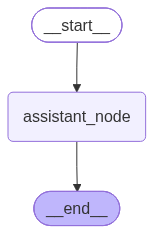

In [4]:
from langgraph.graph import StateGraph, START, END

graph_builder = StateGraph(AgentState)

# Node registration
graph_builder.add_node("assistant_node", assistant_node)

# Add edges to nodes
graph_builder.add_edge(START, "assistant_node")
graph_builder.add_edge("assistant_node", END)

graph = graph_builder.compile()
graph

In [5]:
response = graph.invoke({"messages": [{"role": "user", "content": "I am Bapurao"}]})
response

{'messages': [HumanMessage(content='I am Bapurao', additional_kwargs={}, response_metadata={}, id='3e2bc531-9550-4cfd-b21c-beccb29b3500'),
  AIMessage(content="Namaste Bapurao! It's nice to meet you. Is there anything I can help you with or would you like to chat?", additional_kwargs={}, response_metadata={'model': 'llama3.2:latest', 'created_at': '2026-10-27T06:21:06.4110574Z', 'done': True, 'done_reason': 'stop', 'total_duration': 17268008300, 'load_duration': 10644039300, 'prompt_eval_count': 30, 'prompt_eval_duration': 1430877000, 'eval_count': 29, 'eval_duration': 5142987000, 'logprobs': None, 'model_name': 'llama3.2:latest', 'model_provider': 'ollama'}, id='lc_run--01a17c04-c263-74d8-953e-3f476227316d-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 30, 'output_tokens': 29, 'total_tokens': 59})]}

In [6]:
response = graph.invoke({"messages": [{"role": "user", "content": "What is my name?"}]})
response

{'messages': [HumanMessage(content='What is my name?', additional_kwargs={}, response_metadata={}, id='075e93b0-790b-44d0-be7d-385d0e11b88e'),
  AIMessage(content="I don't have any information about your name. I'm a conversational AI, and our conversation just started. I don't retain any information about individual users. If you'd like to share your name, I'd be happy to chat with you!", additional_kwargs={}, response_metadata={'model': 'llama3.2:latest', 'created_at': '2026-10-27T06:21:18.0047705Z', 'done': True, 'done_reason': 'stop', 'total_duration': 9196017400, 'load_duration': 39992200, 'prompt_eval_count': 30, 'prompt_eval_duration': 714903000, 'eval_count': 52, 'eval_duration': 8421602000, 'logprobs': None, 'model_name': 'llama3.2:latest', 'model_provider': 'ollama'}, id='lc_run--01a17c05-0f46-75f8-a676-e24d1013a1ce-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 30, 'output_tokens': 52, 'total_tokens': 82})]}

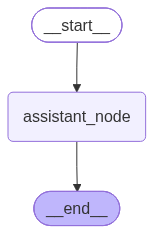

In [12]:
#Short term memory check point added

from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import MemorySaver

short_term_memory = MemorySaver()
graph_builder = StateGraph(AgentState)

# Node registration
graph_builder.add_node("assistant_node", assistant_node)

# Add edges to nodes
graph_builder.add_edge(START, "assistant_node")
graph_builder.add_edge("assistant_node", END)

graph = graph_builder.compile(checkpointer=short_term_memory)
graph

In [13]:
config = {"configurable": {"thread_id": "Tourist_places_in_India"}}
response = graph.invoke({"messages": [{"role": "user", "content": "I am Bapurao"}]}, config)
response

{'messages': [HumanMessage(content='I am Bapurao', additional_kwargs={}, response_metadata={}, id='adc6bb2e-f8a9-4356-98bb-36118c4e91a6'),
  AIMessage(content="Namaste Bapurao! It's nice to meet you. Is there something I can help you with or would you like to chat?", additional_kwargs={}, response_metadata={'model': 'llama3.2:latest', 'created_at': '2026-10-27T06:24:19.5328596Z', 'done': True, 'done_reason': 'stop', 'total_duration': 6389745700, 'load_duration': 24767500, 'prompt_eval_count': 30, 'prompt_eval_duration': 613496000, 'eval_count': 29, 'eval_duration': 5723443000, 'logprobs': None, 'model_name': 'llama3.2:latest', 'model_provider': 'ollama'}, id='lc_run--01a17c07-df55-724d-a4e6-9db67b1e0fe5-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 30, 'output_tokens': 29, 'total_tokens': 59})]}

In [14]:
response = graph.invoke({"messages": [{"role": "user", "content": "What is my name?"}]}, config)
response

{'messages': [HumanMessage(content='I am Bapurao', additional_kwargs={}, response_metadata={}, id='adc6bb2e-f8a9-4356-98bb-36118c4e91a6'),
  AIMessage(content="Namaste Bapurao! It's nice to meet you. Is there something I can help you with or would you like to chat?", additional_kwargs={}, response_metadata={'model': 'llama3.2:latest', 'created_at': '2026-10-27T06:24:19.5328596Z', 'done': True, 'done_reason': 'stop', 'total_duration': 6389745700, 'load_duration': 24767500, 'prompt_eval_count': 30, 'prompt_eval_duration': 613496000, 'eval_count': 29, 'eval_duration': 5723443000, 'logprobs': None, 'model_name': 'llama3.2:latest', 'model_provider': 'ollama'}, id='lc_run--01a17c07-df55-724d-a4e6-9db67b1e0fe5-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 30, 'output_tokens': 29, 'total_tokens': 59}),
  HumanMessage(content='What is my name?', additional_kwargs={}, response_metadata={}, id='5cfa97e0-3ec0-4505-824b-b1780db499ee'),
  AIMessage(content='You mentioned 

In [15]:
config = {"configurable": {"thread_id": "Global_warming"}}
response = graph.invoke({"messages": [{"role": "user", "content": "What is my name?"}]}, config)
response

{'messages': [HumanMessage(content='What is my name?', additional_kwargs={}, response_metadata={}, id='1bce3b86-30cf-49c3-9f68-6bce1165ed94'),
  AIMessage(content="I don't have any information about your name. I'm a large language model, I don't have the ability to store or access personal information about individuals. Each time you interact with me, it's a new conversation and I don't retain any information from previous conversations. If you'd like to share your name with me, I'd be happy to chat with you!", additional_kwargs={}, response_metadata={'model': 'llama3.2:latest', 'created_at': '2026-10-27T06:25:07.9669933Z', 'done': True, 'done_reason': 'stop', 'total_duration': 17012900800, 'load_duration': 30601800, 'prompt_eval_count': 30, 'prompt_eval_duration': 213707000, 'eval_count': 76, 'eval_duration': 16732124000, 'logprobs': None, 'model_name': 'llama3.2:latest', 'model_provider': 'ollama'}, id='lc_run--01a17c08-7302-733a-857e-8f6d36bb740f-0', tool_calls=[], invalid_tool_call

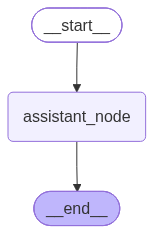

In [18]:
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.sqlite import SqliteSaver
import sqlite3

db_path = "zenapp.db"
sqllite_connection = sqlite3.connect(db_path, check_same_thread=False)
short_term_memory = SqliteSaver(sqllite_connection)
graph_builder = StateGraph(AgentState)

# Node registration
graph_builder.add_node("assistant_node", assistant_node)

# Add edges to nodes
graph_builder.add_edge(START, "assistant_node")
graph_builder.add_edge("assistant_node", END)

graph = graph_builder.compile(checkpointer=short_term_memory)
graph

In [19]:
config = {"configurable": {"thread_id": "Tourist_places_in_India"}}
response = graph.invoke({"messages": [{"role": "user", "content": "I am Bapurao"}]}, config)
response

{'messages': [HumanMessage(content='I am Anand', additional_kwargs={}, response_metadata={}, id='b7a23023-fa4b-4287-ab04-5831c54a2e85'),
  AIMessage(content="Namaste Anand! It's nice to meet you. Is there something I can help you with or would you like to chat?", additional_kwargs={}, response_metadata={'model': 'llama3.2:latest', 'created_at': '2026-10-27T06:28:50.3673474Z', 'done': True, 'done_reason': 'stop', 'total_duration': 7632926800, 'load_duration': 95928400, 'prompt_eval_count': 29, 'prompt_eval_duration': 842076000, 'eval_count': 28, 'eval_duration': 6620095000, 'logprobs': None, 'model_name': 'llama3.2:latest', 'model_provider': 'ollama'}, id='lc_run--01a17c0b-fc52-761d-8c41-37aeb29cfc63-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 29, 'output_tokens': 28, 'total_tokens': 57}),
  HumanMessage(content='I am Bapurao', additional_kwargs={}, response_metadata={}, id='bc328086-99f1-4a33-8794-e9b8aa2dce9b'),
  AIMessage(content='Namaste Bapurao! How c

In [20]:
response = graph.invoke({"messages": [{"role": "user", "content": "What is my name?"}]}, config)
response

{'messages': [HumanMessage(content='I am Anand', additional_kwargs={}, response_metadata={}, id='b7a23023-fa4b-4287-ab04-5831c54a2e85'),
  AIMessage(content="Namaste Anand! It's nice to meet you. Is there something I can help you with or would you like to chat?", additional_kwargs={}, response_metadata={'model': 'llama3.2:latest', 'created_at': '2026-10-27T06:28:50.3673474Z', 'done': True, 'done_reason': 'stop', 'total_duration': 7632926800, 'load_duration': 95928400, 'prompt_eval_count': 29, 'prompt_eval_duration': 842076000, 'eval_count': 28, 'eval_duration': 6620095000, 'logprobs': None, 'model_name': 'llama3.2:latest', 'model_provider': 'ollama'}, id='lc_run--01a17c0b-fc52-761d-8c41-37aeb29cfc63-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 29, 'output_tokens': 28, 'total_tokens': 57}),
  HumanMessage(content='I am Bapurao', additional_kwargs={}, response_metadata={}, id='bc328086-99f1-4a33-8794-e9b8aa2dce9b'),
  AIMessage(content='Namaste Bapurao! How c

In [21]:
# Tools definition
from langchain_community.tools import tool

@tool
def get_weather(city: str) -> str:
    """Get weather for a city"""
    return f"The weather in the city {city} is Sunny"

@tool
def get_stock_price(stock: str) -> str:
    """Returns the stock price for a given stock"""
    return f"The stock price of {stock} is 25.50"

get_weather
get_stock_price
print('Tools are ready')

Tools are ready


C:\Users\bg108836\AppData\Local\Temp\ipykernel_9808\2657010362.py:2: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.tools import tool


In [22]:
from langgraph.config import get_store, get_config

@tool
def save_memory(fact: str) -> str:
    """Save an important fact about the user for future conversations
    (e.g. their name, workplace, or a stated preference)."""
    store = get_store()
    user_id = get_config()["configurable"]["user_id"]
    store.put(("memories", user_id), fact[:40], {"text": fact})
    return f"Saved: {fact}"

@tool
def recall_memories(query: str) -> str:
    """Search saved facts about the user relevant to the query.
    ALWAYS call this before claiming you don't know something about the user."""
    store = get_store()
    user_id = get_config()["configurable"]["user_id"]
    results = store.search(("memories", user_id), query=query, limit=5)
    if not results:
        return "No relevant memories found."
    return "\n".join(f"- {r.value['text']}" for r in results)

print("Memory tools ready: save_memory, recall_memories")

Memory tools ready: save_memory, recall_memories


In [23]:
# Example - Long term memory
# Creating an agent
from langchain.agents import create_agent
from langgraph.store.memory import InMemoryStore

long_term_memory = InMemoryStore()

agent = create_agent(
    model=model,
    tools=[get_weather, get_stock_price, save_memory, recall_memories],
    system_prompt=(
        "You are a helpful assistant with long-term memory. "
        "When the user shares a personal fact, call save_memory, then briefly confirm. "
        "When asked what you know about the user, ALWAYS call recall_memories first. "
        "Your final answer MUST be based only on the tool output returned -- restate those facts plainly. "
        "Never say you don't know something if the tool result contains it."
    ),
    store=long_term_memory
)
print('AI agent is ready')

AI agent is ready


In [24]:
config = {"configurable": {"thread_id": "Tourist_places_in_India", "user_id": "bapurao"}}
response = agent.invoke({"messages": [{"role": "user", "content": "I am Anand"}]}, config)
response

{'messages': [HumanMessage(content='I am Anand', additional_kwargs={}, response_metadata={}, id='258d0fe3-0d23-4c93-96fe-a3ffcff45ee4'),
  AIMessage(content='', additional_kwargs={}, response_metadata={'model': 'llama3.2:latest', 'created_at': '2026-10-27T06:31:21.1583248Z', 'done': True, 'done_reason': 'stop', 'total_duration': 20994738100, 'load_duration': 115115300, 'prompt_eval_count': 391, 'prompt_eval_duration': 17360461000, 'eval_count': 14, 'eval_duration': 3390014000, 'logprobs': None, 'model_name': 'llama3.2:latest', 'model_provider': 'ollama'}, id='lc_run--01a17c0e-1538-73ee-9698-eed8248c059c-0', tool_calls=[{'name': 'recall_memories', 'args': {'query': 'User'}, 'id': '0c75b298-4197-4f8a-bf77-5c3030b100c8', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 391, 'output_tokens': 14, 'total_tokens': 405}),
  ToolMessage(content='No relevant memories found.', name='recall_memories', id='1ec39903-ca59-429a-8aba-cb3625d33f7d', tool_call_id='0c75b298-41

In [25]:
response = agent.invoke({"messages": [{"role": "user", "content": "What is my name?"}]}, config)
response

{'messages': [HumanMessage(content='What is my name?', additional_kwargs={}, response_metadata={}, id='50e77dff-6597-42d0-8ae1-6bc7c92efc5e'),
  AIMessage(content='', additional_kwargs={}, response_metadata={'model': 'llama3.2:latest', 'created_at': '2026-10-27T06:31:49.2031853Z', 'done': True, 'done_reason': 'stop', 'total_duration': 18091565100, 'load_duration': 590256400, 'prompt_eval_count': 392, 'prompt_eval_duration': 12878504000, 'eval_count': 17, 'eval_duration': 4498366000, 'logprobs': None, 'model_name': 'llama3.2:latest', 'model_provider': 'ollama'}, id='lc_run--01a17c0e-8e25-7229-a5a1-2735b76573a1-0', tool_calls=[{'name': 'recall_memories', 'args': {'query': 'What is the user'}, 'id': 'cdbe1d92-0145-4805-818c-11d76def57d6', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 392, 'output_tokens': 17, 'total_tokens': 409}),
  ToolMessage(content='No relevant memories found.', name='recall_memories', id='781cafd5-9976-4089-8432-fb49efad1980', tool_ca

In [26]:
config_2 = {"configurable": {"thread_id": "Global_warming", "user_id": "bapurao"}}
response = agent.invoke({"messages": [{"role": "user", "content": "What is my name?"}]}, config_2)
response

{'messages': [HumanMessage(content='What is my name?', additional_kwargs={}, response_metadata={}, id='965c2ac4-5322-4808-832a-ca1884f60d00'),
  AIMessage(content='', additional_kwargs={}, response_metadata={'model': 'llama3.2:latest', 'created_at': '2026-10-27T06:32:12.1467186Z', 'done': True, 'done_reason': 'stop', 'total_duration': 16614851600, 'load_duration': 57142100, 'prompt_eval_count': 392, 'prompt_eval_duration': 13068357000, 'eval_count': 14, 'eval_duration': 3390697000, 'logprobs': None, 'model_name': 'llama3.2:latest', 'model_provider': 'ollama'}, id='lc_run--01a17c0e-ed86-714c-832a-4d728447d7ed-0', tool_calls=[{'name': 'recall_memories', 'args': {'query': 'name'}, 'id': 'f81031e2-3c94-460e-b237-1ae4b95f20e5', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 392, 'output_tokens': 14, 'total_tokens': 406}),
  ToolMessage(content='No relevant memories found.', name='recall_memories', id='63c046c3-251e-48af-9008-b4810adf9267', tool_call_id='f81031

In [ ]:
onfig_3 = {"configurable": {"thread_id": "Tourist_places_in_India", "user_id": "tom"}}
response = agent.invoke({"messages": [{"role": "user", "content": "What is my name?"}]}, config_3)
response

NameError: name 'config_3' is not defined